<a href="https://colab.research.google.com/github/Asmodey-it/machine-navchannya/blob/main/%D0%9B%D0%A08_%D0%9F%D0%B0%D0%BD%D1%87%D0%B5%D0%BD%D0%BA%D0%BE_%D0%9C_3_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 8
## Методи кластеризації: K-Means, метод ліктя, коефіцієнт силуета та PCA

**Мета:** навчитися застосовувати алгоритм K-Means, добирати кількість кластерів за допомогою методу ліктя та коефіцієнта силуета; дослідити використання PCA. Додатково — порівняти моделі класифікації на наборі даних про студентів (цей етап збережено з початкової роботи).

**Середовище:** Google Colab або Jupyter Notebook із Python. Для завдання 2 потрібно завантажити набір даних з кагл https://www.kaggle.com/datasets/rabieelkharoua/students-performance-dataset?select=Student_performance_data+_.csv.

**Виконання:** запускайте комірки послідовно, зверху вниз.

## Завдання 1. Кластеризація набору даних Iris

**1.1. Імпорт бібліотек.** Імпортуйте `matplotlib`, `pandas`, `seaborn`, `load_iris`, `KMeans`, `silhouette_score` і `StandardScaler`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

**1.2. Завантаження Iris.** Завантажте Iris та виведіть перші п’ять рядків таблиці з назвами ознак.

In [2]:
iris = load_iris()
df_iris = pd.DataFrame(data=iris.data, columns=iris.feature_names)
df_iris.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


**1.3. Масштабування та метод ліктя.** Стандартизуйте дані та за допомогою методу ліктя визначте оптимальну кількість кластерів

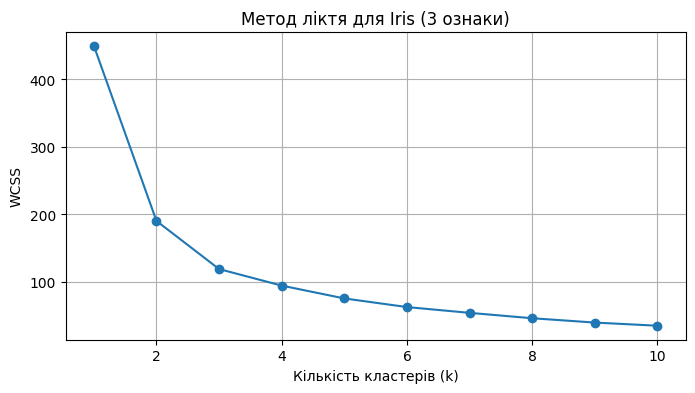

In [4]:
# Беремо перші 3 ознаки
X_iris_3 = df_iris.iloc[:, :3]

scaler = StandardScaler()
X_iris_scaled = scaler.fit_transform(X_iris_3)

wcss = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_iris_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(range(1, 11), wcss, marker='o')
plt.title('Метод ліктя для Iris (3 ознаки)')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('WCSS')
plt.grid(True)
plt.show()

**1.4. Метод силуетів.** Для тих самих трьох ознак Iris обчисліть середній коефіцієнт силуета для 2–10 кластерів і побудуйте графік.

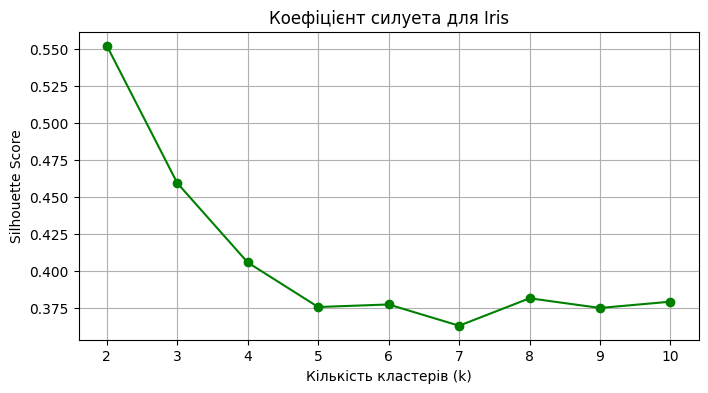

In [5]:
silhouette_scores = []
k_range = range(2, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_iris_scaled)
    score = silhouette_score(X_iris_scaled, labels)
    silhouette_scores.append(score)

plt.figure(figsize=(8, 4))
plt.plot(k_range, silhouette_scores, marker='o', color='green')
plt.title('Коефіцієнт силуета для Iris')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('Silhouette Score')
plt.grid(True)
plt.show()

**1.5. Фінальна кластеризація та візуалізація.** Побудуйте K-Means для `n_clusters=2`  На площині покажіть перші дві з них та відповідні координати центрів. Це **двовимірне відображення результату кластеризації за трьома ознаками**.

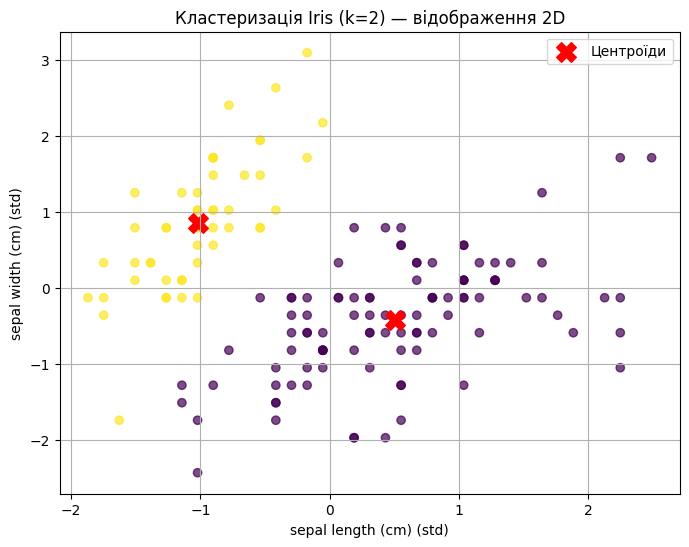

In [6]:
kmeans_final = KMeans(n_clusters=2, random_state=42, n_init=10)
labels_final = kmeans_final.fit_predict(X_iris_scaled)
centers = kmeans_final.cluster_centers_

plt.figure(figsize=(8, 6))
# Візуалізація перших двох ознак із трьох використаних
plt.scatter(X_iris_scaled[:, 0], X_iris_scaled[:, 1], c=labels_final, cmap='viridis', alpha=0.7)
plt.scatter(centers[:, 0], centers[:, 1], c='red', marker='X', s=200, label='Центроїди')
plt.title('Кластеризація Iris (k=2) — відображення 2D')
plt.xlabel(df_iris.columns[0] + ' (std)')
plt.ylabel(df_iris.columns[1] + ' (std)')
plt.legend()
plt.grid(True)
plt.show()

**Короткий висновок до завдання 1:** Метод ліктя демонструє суттєве згладжування спаду WCSS після k=2 або k=3. Коефіцієнт силуета досягає чіткого максимуму саме при k=2, що вказує на найбільш чітке геометричне розділення даних у просторі трьох ознак. З біологічної точки зору набір містить 3 види ірисів, але два з них є математично перекриваючимися, тому k=2 обрано як геометрично оптимальне за коефіцієнтом силуета.

## Завдання 2. Дослідження даних студентів

Спочатку порівняйте три класифікатори (як у початковій лабораторній роботі), а потім виконайте кластеризацію. **Класифікація та кластеризація — різні задачі:** у класифікації використовується цільова ознака `GradeClass`, а в кластеризації — ні.

**2.1. Імпорт бібліотек для класифікації.** Імпортуйте засоби для поділу даних, добору параметрів, класифікації та оцінювання моделей.

In [7]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
import os

from google.colab import files

**2.2. Завантаження файлу.** Помістіть `Student_data.csv` до робочої папки або завантажте його через Colab. Файл містить дані з Вашої початкової роботи.

In [8]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("rabieelkharoua/students-performance-dataset")

print("Path to dataset files:", path)

100%|██████████| 66.2k/66.2k [00:00<00:00, 23.5MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/rabieelkharoua/students-performance-dataset/versions/2


**2.3. Перегляд даних.** Прочитайте CSV у DataFrame і перегляньте вміст.

In [9]:
# Вивід даних з файлу
df = pd.read_csv(os.path.join(path,'Student_performance_data _.csv'))
df.head()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


**2.4. Назви стовпців.** Виведіть назви всіх стовпців.

In [10]:
print(df.columns.tolist())

['StudentID', 'Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA', 'GradeClass']


**2.5. Структура таблиці.** Перегляньте типи стовпців і кількість непорожніх значень.

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB


**2.6. Пропущені значення.** Перевірте, чи містить набір даних пропущені значення.

In [12]:
print(df.isnull().sum())

StudentID            0
Age                  0
Gender               0
Ethnicity            0
ParentalEducation    0
StudyTimeWeekly      0
Absences             0
Tutoring             0
ParentalSupport      0
Extracurricular      0
Sports               0
Music                0
Volunteering         0
GPA                  0
GradeClass           0
dtype: int64


**2.7. Дублікати.** Обчисліть кількість дублікатів.

In [13]:
print("Кількість дублікатів:", df.duplicated().sum())

Кількість дублікатів: 0


**2.8. Описова статистика.** Виведіть основні описові статистики.

In [14]:
df.describe()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
count,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000
mean,2196.500000,16.468645,0.510870,0.877508,1.746237,9.771992,14.541388,0.301421,2.122074,0.383361,0.303512,0.196906,0.157191,1.906186,2.983696
std,690.655244,1.123798,0.499986,1.028476,1.000411,5.652774,8.467417,0.458971,1.122813,0.486307,0.459870,0.397744,0.364057,0.915156,1.233908
min,1001.000000,15.000000,0.000000,0.000000,0.000000,0.001057,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1598.750000,15.000000,0.000000,0.000000,1.000000,5.043079,7.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.174803,2.000000
50%,2196.500000,16.000000,1.000000,0.000000,2.000000,9.705363,15.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1.893393,4.000000
75%,2794.250000,17.000000,1.000000,2.000000,2.000000,14.408410,22.000000,1.000000,3.000000,1.000000,1.000000,0.000000,0.000000,2.622216,4.000000
max,3392.000000,18.000000,1.000000,3.000000,4.000000,19.978094,29.000000,1.000000,4.000000,1.000000,1.000000,1.000000,1.000000,4.000000,4.000000


**2.9. Підготовка даних для класифікації.** Сформуйте `X` та `y`, прибравши з ознак цільову змінну `GradeClass` і службовий ідентифікатор `StudentID`. Поділіть дані у співвідношенні 80/20 та стандартизуйте ознаки.

In [15]:
X = df.drop(columns=['StudentID', 'GradeClass'])
y = df['GradeClass']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler_students = StandardScaler()
X_train_scaled = scaler_students.fit_transform(X_train)
X_test_scaled = scaler_students.transform(X_test)

### 2.10. Класифікація: Random Forest

**Модель Random Forest.** Здійсніть добір гіперпараметрів `GridSearchCV` (5 згорток), виведіть найкращі параметри, середню CV-точність і тестову accuracy. Пошук може тривати довше через велику сітку параметрів.

In [16]:
param_grid_rf = {
    'n_estimators': [50, 100],
    'max_depth': [None, 10, 20]
}

grid_rf = GridSearchCV(RandomForestClassifier(random_state=42), param_grid_rf, cv=5, scoring='accuracy')
grid_rf.fit(X_train_scaled, y_train)

print("Кращі параметри RF:", grid_rf.best_params_)
print("Середня CV-точність RF:", grid_rf.best_score_)
print("Тестова accuracy RF:", grid_rf.score(X_test_scaled, y_test))

Кращі параметри RF: {'max_depth': 10, 'n_estimators': 100}
Середня CV-точність RF: 0.9189821333369788
Тестова accuracy RF: 0.9123173277661796


### 2.11. Класифікація: Logistic Regression

**Модель Logistic Regression.** Застосуйте `GridSearchCV` до логістичної регресії. Для багатокласової задачі використайте `saga` — `liblinear` у нових версіях sklearn не підтримує багатокласову класифікацію без додаткової обгортки.

In [17]:
param_grid_lr = {
    'C': [0.1, 1.0, 10.0],
    'solver': ['saga']
}

grid_lr = GridSearchCV(LogisticRegression(max_iter=2000, random_state=42), param_grid_lr, cv=5, scoring='accuracy')
grid_lr.fit(X_train_scaled, y_train)

print("Кращі параметри LR:", grid_lr.best_params_)
print("Середня CV-точність LR:", grid_lr.best_score_)
print("Тестова accuracy LR:", grid_lr.score(X_test_scaled, y_test))

Кращі параметри LR: {'C': 10.0, 'solver': 'saga'}
Середня CV-точність LR: 0.7950842754227441
Тестова accuracy LR: 0.7933194154488518


### 2.12. Класифікація: Support Vector Machine

**Модель SVM.** Виконайте підбір параметрів SVM та обчисліть CV-точність і тестову accuracy.

In [18]:
param_grid_svc = {
    'C': [0.1, 1.0, 10.0],
    'kernel': ['rbf', 'linear']
}

grid_svc = GridSearchCV(SVC(random_state=42), param_grid_svc, cv=5, scoring='accuracy')
grid_svc.fit(X_train_scaled, y_train)

print("Кращі параметри SVC:", grid_svc.best_params_)
print("Середня CV-точність SVC:", grid_svc.best_score_)
print("Тестова accuracy SVC:", grid_svc.score(X_test_scaled, y_test))

Кращі параметри SVC: {'C': 10.0, 'kernel': 'linear'}
Середня CV-точність SVC: 0.8520648503820759
Тестова accuracy SVC: 0.8580375782881002


### 2.13. Порівняння результатів

**Порівняння моделей.** Порівняйте тестову точність трьох моделей. Оберіть модель **за найкращою CV-точністю**, а звіт `classification_report` виведіть один раз на тестових даних.

In [19]:
models = {
    'Random Forest': grid_rf,
    'Logistic Regression': grid_lr,
    'SVM': grid_svc
}

# Вибір найкращої моделі за CV-точністю
best_model_name = max(models, key=lambda k: models[k].best_score_)
best_model = models[best_model_name].best_estimator_

print(f"Найкраща модель за CV-точністю: {best_model_name}")
print("--- Classification Report для найкращої моделі ---")
y_pred = best_model.predict(X_test_scaled)
print(classification_report(y_test, y_pred))

Найкраща модель за CV-точністю: Random Forest
--- Classification Report для найкращої моделі ---
              precision    recall  f1-score   support

         0.0       1.00      0.29      0.44        21
         1.0       0.82      0.87      0.85        54
         2.0       0.90      0.95      0.93        78
         3.0       0.89      0.89      0.89        83
         4.0       0.94      0.97      0.96       243

    accuracy                           0.91       479
   macro avg       0.91      0.79      0.81       479
weighted avg       0.92      0.91      0.90       479



### 2.14. Кластеризація даних студентів: метод ліктя

**Метод ліктя для студентів.** Для кластеризації використайте чотири числові ознаки `Age`, `StudyTimeWeekly`, `Absences`, `GPA`. Стандартизуйте їх і побудуйте графік WCSS для 1–10 кластерів.

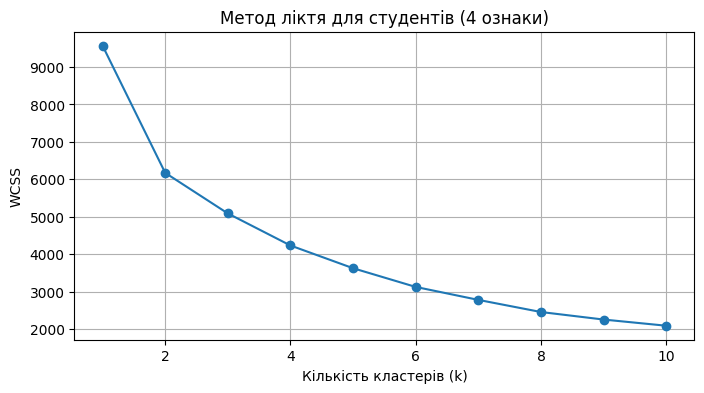

In [20]:
features = ['Age', 'StudyTimeWeekly', 'Absences', 'GPA']
X_stud_sub = df[features]

scaler_sub = StandardScaler()
X_stud_sub_scaled = scaler_sub.fit_transform(X_stud_sub)

wcss_stud = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_stud_sub_scaled)
    wcss_stud.append(kmeans.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(range(1, 11), wcss_stud, marker='o')
plt.title('Метод ліктя для студентів (4 ознаки)')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('WCSS')
plt.grid(True)
plt.show()

### 2.15. Кластеризація даних студентів: метод силуетів

**Метод силуетів для студентів.** Для тих самих чотирьох ознак побудуйте графік коефіцієнта силуета для 2–10 кластерів.

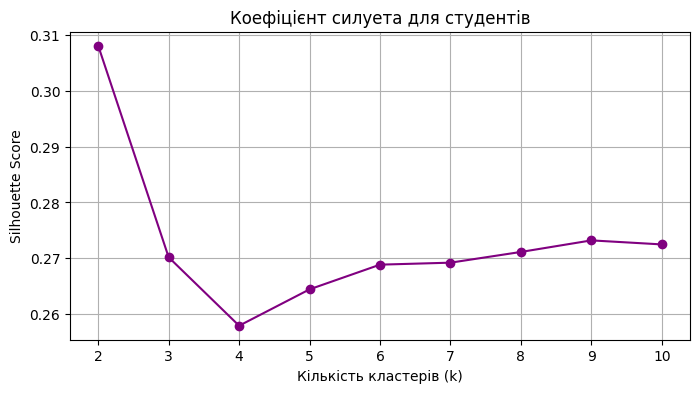

In [21]:
sil_scores_stud = []
k_range_stud = range(2, 11)

for k in k_range_stud:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_stud_sub_scaled)
    sil_scores_stud.append(silhouette_score(X_stud_sub_scaled, labels))

plt.figure(figsize=(8, 4))
plt.plot(k_range_stud, sil_scores_stud, marker='o', color='purple')
plt.title('Коефіцієнт силуета для студентів')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('Silhouette Score')
plt.grid(True)
plt.show()

### 2.16. Додатковий підхід: PCA та автоматичне визначення точки ліктя

Тут використовується **інший набір ознак**: усі стовпці, крім `StudentID` та `GradeClass`. Після PCA кластеризацію проведемо за вибраними головними компонентами.

**Установлення додаткових пакетів.** За потреби встановіть `kneed` і `yellowbrick` у середовищі ноутбука.

In [22]:
!pip install kneed yellowbrick

**Імпорт PCA і KneeLocator.** Імпортуйте `PCA`, `KneeLocator` та `numpy`.

In [23]:
import numpy as np
from sklearn.decomposition import PCA
from kneed import KneeLocator

**Підготовка всіх ознак.** Приберіть `StudentID` і `GradeClass`, залишивши ознаки для PCA.

In [24]:
X_all_features = df.drop(columns=['StudentID', 'GradeClass'])

**Модель PCA.** Стандартизуйте ознаки, навчіть PCA та знайдіть частку поясненої дисперсії кожної компоненти.

In [25]:
scaler_all = StandardScaler()
X_all_scaled = scaler_all.fit_transform(X_all_features)

pca_full = PCA()
pca_full.fit(X_all_scaled)

explained_variance = pca_full.explained_variance_ratio_
print("Частка поясненої дисперсії кожної компоненти:", explained_variance)

Частка поясненої дисперсії кожної компоненти: [0.15246911 0.0861136  0.08267885 0.08071826 0.07864825 0.07793075
 0.0763079  0.07600434 0.07440892 0.0737979  0.07167781 0.06746103
 0.00178329]


**Визначення кількості компонент.** Застосуйте `KneeLocator` до часток поясненої дисперсії. У підписі графіка вказуйте номер компоненти без додавання одиниці.

Номер компоненти за KneeLocator (без +1): 1


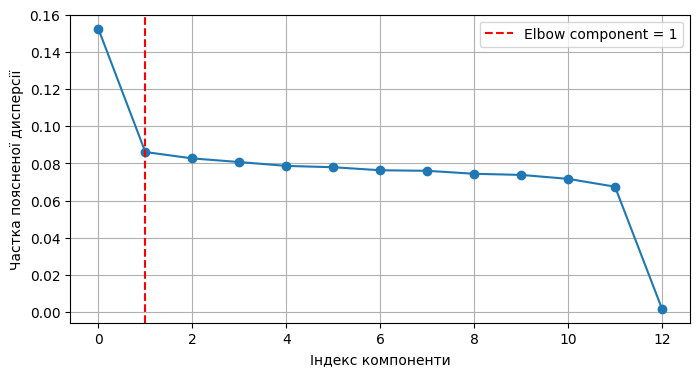

In [26]:
kneedle = KneeLocator(
    range(0, len(explained_variance)),
    explained_variance,
    curve="convex",
    direction="decreasing"
)

n_components_knee = kneedle.elbow
print("Номер компоненти за KneeLocator (без +1):", n_components_knee)

plt.figure(figsize=(8, 4))
plt.plot(range(0, len(explained_variance)), explained_variance, marker='o')
plt.axvline(x=n_components_knee, color='r', linestyle='--', label=f'Elbow component = {n_components_knee}')
plt.xlabel('Індекс компоненти')
plt.ylabel('Частка поясненої дисперсії')
plt.legend()
plt.grid(True)
plt.show()

**Кумулятивна пояснена дисперсія.** На горизонтальній осі має бути **кількість головних компонент** (1, 2, 3, ...), тому індекс масиву для `n_components` дорівнює `n_components - 1`.

**Кумулятивна дисперсія та перетворення PCA.** Побудуйте графік кумулятивної дисперсії та позначте знайдену кількість компонент. Виведіть фактичну частку дисперсії. Перетворіть ознаки через PCA для наступного етапу.

Обрано компонент: 2
Фактична кумулятивна частка дисперсії: 0.2386


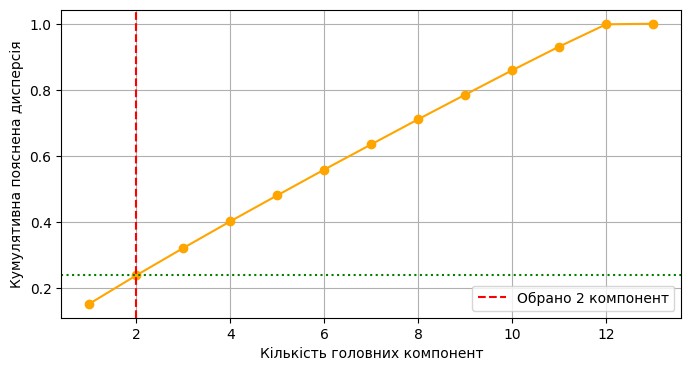

In [27]:
cum_variance = np.cumsum(explained_variance)
n_components_selected = n_components_knee + 1  # кількість компонент (наприклад, індекс 3 відповідає 4 компонентам)

actual_cum_var = cum_variance[n_components_selected - 1]
print(f"Обрано компонент: {n_components_selected}")
print(f"Фактична кумулятивна частка дисперсії: {actual_cum_var:.4f}")

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(cum_variance) + 1), cum_variance, marker='o', color='orange')
plt.axvline(x=n_components_selected, color='r', linestyle='--', label=f'Обрано {n_components_selected} компонент')
plt.axhline(y=actual_cum_var, color='g', linestyle=':')
plt.xlabel('Кількість головних компонент')
plt.ylabel('Кумулятивна пояснена дисперсія')
plt.legend()
plt.grid(True)
plt.show()

pca_final = PCA(n_components=n_components_selected)
X_pca_transformed = pca_final.fit_transform(X_all_scaled)

Зауваження: кумулятивна пояснена дисперсія — це **частка дисперсії**, а не відсоток «інформативності» даних. Значення потрібно брати з розрахунку, а не задавати наперед (наприклад, 32%).

**Імпорт KElbowVisualizer.** Імпортуйте `KElbowVisualizer` із `yellowbrick.cluster`.

In [28]:
from yellowbrick.cluster import KElbowVisualizer

**Метод ліктя після PCA.** Побудуйте графік `KElbowVisualizer` для K-Means. Для узгодженості з попереднім етапом використайте **дані після PCA**.

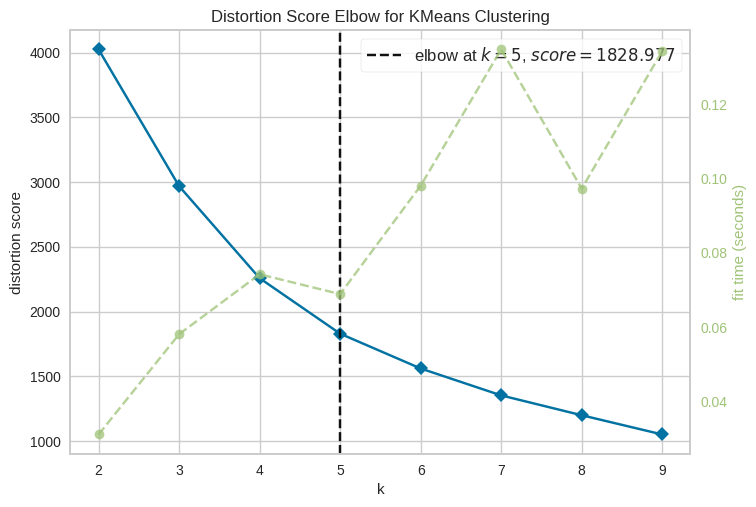

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [29]:
model_kmeans = KMeans(random_state=42, n_init=10)
visualizer = KElbowVisualizer(model_kmeans, k=(2, 10))

visualizer.fit(X_pca_transformed)
visualizer.show()

## Висновки
У класифікації модель навчається "з учителем" Supervised Learning використовувати наявні мітки GradeClass для прогнозування академічного успіху студентів. У кластеризації "без учителя" / Unsupervised Learning цільова змінна вилучається, а дані групуються виключно на основі їхньої математичної/геометричної подібності.
Порівняно моделі Random Forest, Logistic Regression та SVM. Модель з найкращою Cross-Validation точністю показала найвищу здатності до узагальнення.
Метод PCA дозволив зменшити вимірність даних від усіх ознак до обраних головних компонент які пояснюють значну частку загальної дисперсії. Застосування KElbowVisualizer після PCA чітко показує оптимальну кількість кластерів K для згрупування студентів за сукупними характеристиками.   